- Importing the neccesary libraries for ETL, regression decision trees , dataframes,plotting and more

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE = 42

In [4]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
df.head()
print("Shape:", df.shape)
print()
df.info()

Shape: (320, 7)

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   AdvertisingSpend_KES  320 non-null    int64
 1   StoreVisits           320 non-null    int64
 2   DiscountPercent       320 non-null    int64
 3   Region                320 non-null    str  
 4   CustomerSegment       320 non-null    str  
 5   ProductCategory       320 non-null    str  
 6   Sales_KES             320 non-null    int64
dtypes: int64(4), str(3)
memory usage: 24.1 KB


- The number or rows are 320, and number of columns are 7.

- The numeric columns are AdvertisingSpend_KES,storeVisits,DiscountPercent,Sales_KES

- The categorical variables are region,customersegment and product category

- One row represent a sale record.

- We are here to predict the sales it is our prediction target.

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


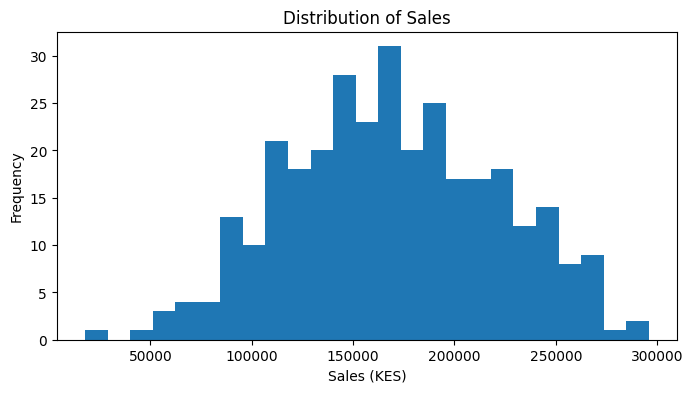

In [8]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
df["Sales_KES"].describe()
plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()



The target variable as we know is sales_KES, with a sales varying from 17805kes to 295825kes and has a pretty wide spread with median 168462kes and average sales to be 169252.44kes. 

- The extreme high values such as 290,000kes can show that they business might perform extremely well in certain regions  , or in certain segment or due to enough advertisement spent and that can help the decision makers spread this sucees throughout.Instead of assuming its an error in the dataset of sales

- Extreme low values such as around the 20,000ksh , can also let us know where the business needs improvemtn on the various segemtns, regions they are laacking in or can even be due to low advertisiment or low sales in a particular product due to people in that region not using that product, this will provide the business to implement or produce more product for that particular region.





Business question: Can available business characteristics be used to estimate sales?
• Analytical task: supervised regression.
• Target: Sales_KES.
• Features: AdvertisingSpend_KES, StoreVisits, DiscountPercent, Region, CustomerSegment,
ProductCategory.

Yes they can but will not give to a full extent give accurate  predictions, because we need to look at how the the the independent variables are correlated with one another like for example is advertising spend have a strong relationship with the amount of store visits .This will help us make a better model.

In [9]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


In [11]:
numeric_features = [
"AdvertisingSpend_KES",
"StoreVisits",
"DiscountPercent"
]
categorical_features = [
"Region",
"CustomerSegment",
"ProductCategory"
]

In [13]:
numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
("num", numeric_pipeline, numeric_features),
("cat", categorical_pipeline, categorical_features)
])